# t-SNE of EEG latent representations

Latent tokens are pooled on the accelerator before their transfer to CPU. Epochs are sampled reproducibly and evenly across subjects.

In [1]:
import random
import warnings
from pathlib import Path
from time import perf_counter

warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="Importing from timm.models.layers is deprecated")
warnings.filterwarnings("ignore", message="Importing from timm.models.registry is deprecated")
warnings.filterwarnings("ignore", message="enable_nested_tensor is True")

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import yaml
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from torch.utils.data import ConcatDataset, DataLoader, Dataset

from eeg_preprocessing.loaders import CustomDataset, get_subject_ids

ROOT = Path.cwd()

LMDB_PATHS = {
    "BCI2A": "/projects/EEG-foundation-model/RECH202/data_preprocessed_normalized/BCI2A/bci2a.lmdb",
    "FACED": "/projects/EEG-foundation-model/RECH202/data_preprocessed_normalized/FACED/faced.lmdb",
    "PHYSIONETMI": "/projects/EEG-foundation-model/RECH202/data_preprocessed_normalized/PHYSIONETMI/physionetmi.lmdb",
}

MODEL_NAMES = ["cbramod", "eegmamba", "eegpt", "labram", "reve", "lumamba", "luna", "eegfm"]

MODEL_NAME = "reve"
DATASET = "BCI2A"
SEED = 100
BATCH_SIZE = 64
MAX_EPOCHS_PER_SUBJECT = 200
PCA_COMPONENTS = 50
PERPLEXITY = 30
TSNE_ITERATIONS = 1000
NUM_WORKERS = 0
PIN_MEMORY = torch.cuda.is_available()


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class FeatureModel(nn.Module):
    def __init__(self, wrapper):
        super().__init__()
        self.wrapper = wrapper
        self.backbone = wrapper.backbone
        self.chan_conv = getattr(wrapper, "chan_conv", nn.Identity())

    def forward(self, x):
        return self.wrapper.forward_features(x)


def load_wrapper_class(model_name):
    if model_name == "cbramod":
        from utils.wrappers.cbramod import CBraModWrapper
        return CBraModWrapper
    if model_name == "eegmamba":
        from utils.wrappers.eegmamba import EEGMambaWrapper
        return EEGMambaWrapper
    if model_name == "eegpt":
        from utils.wrappers.eegpt import EEGPTWrapper
        return EEGPTWrapper
    if model_name == "labram":
        from utils.wrappers.labram import LaBraMWrapper
        return LaBraMWrapper
    if model_name == "reve":
        from utils.wrappers.reve import ReveWrapper
        return ReveWrapper
    if model_name == "lumamba":
        from utils.wrappers.lumamba import LuMambaWrapper
        return LuMambaWrapper
    if model_name == "luna":
        from utils.wrappers.luna import LUNAWrapper
        return LUNAWrapper
    if model_name == "eegfm":
        from utils.wrappers.eegfm import EEGFMWrapper
        return EEGFMWrapper
    raise ValueError(f"Unknown model: {model_name}")


def load_model_config(model_name):
    with open(ROOT / "utils" / "configs" / f"{model_name}.yaml") as file:
        return yaml.safe_load(file)


def load_model(model_name, dataset, device):
    config = load_model_config(model_name)
    channel_mode = config.get("channel_mode", "mapped")
    lmdb_path = LMDB_PATHS[dataset]
    first_subject = get_subject_ids(Path(lmdb_path))[0]
    sample, _ = CustomDataset(lmdb_path, [first_subject], channel_mode=channel_mode)[0]
    checkpoint = ROOT / config["pretrained_weights"] if config.get("use_pretrained_weights") else None
    if checkpoint is not None and not checkpoint.is_file():
        raise FileNotFoundError(f"Missing pretrained checkpoint: {checkpoint}")
    wrapper = load_wrapper_class(model_name)(
        ckpt_path=str(checkpoint) if checkpoint is not None else None,
        dropout=config.get("dropout", 0.0),
    )
    wrapper.build_backbone(n_channels=sample.shape[0], time_length=sample.shape[1])
    wrapper.freeze_backbone()
    model = FeatureModel(wrapper).to(device)
    parameters = sum(parameter.numel() for parameter in model.backbone.parameters())
    print(f"Backbone parameters: {parameters:,}")
    return model, channel_mode


In [2]:
class SubjectDataset(Dataset):
    def __init__(self, lmdb_path, subject_id, channel_mode, max_epochs, seed):
        self.dataset = CustomDataset(
            lmdb_path,
            subject_ids=[subject_id],
            channel_mode=channel_mode,
            return_ch_names=False,
            scale_factor=1.0,
        )
        self.subject_id = subject_id
        size = len(self.dataset) if max_epochs is None else min(max_epochs, len(self.dataset))
        rng = np.random.default_rng(seed)
        self.indices = np.sort(rng.choice(len(self.dataset), size=size, replace=False))

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        x, y = self.dataset[int(self.indices[index])]
        return x, y, self.subject_id


def build_feature_loader(dataset, channel_mode, seed):
    lmdb_path = LMDB_PATHS[dataset]
    subject_ids = list(get_subject_ids(Path(lmdb_path)))
    datasets = [
        SubjectDataset(
            lmdb_path,
            subject_id,
            channel_mode,
            MAX_EPOCHS_PER_SUBJECT,
            seed + index,
        )
        for index, subject_id in enumerate(subject_ids)
    ]
    loader = DataLoader(
        ConcatDataset(datasets),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY,
        persistent_workers=False,
    )
    return loader, subject_ids


def pool_features(features):
    if features.ndim == 4:
        return features.mean(dim=(1, 2))
    if features.ndim == 3:
        return features.mean(dim=1)
    if features.ndim == 2:
        return features
    raise ValueError(f"Unsupported latent shape: {tuple(features.shape)}")


@torch.inference_mode()
def extract_features(model, loader, device):
    model.eval()
    embeddings = []
    labels = []
    subjects = []
    total = len(loader.dataset)
    processed = 0
    start = perf_counter()
    for batch_index, (x, y, subject_ids) in enumerate(loader):
        x = x.to(device, non_blocking=True).float()
        features = model(model.wrapper.preprocess(x))
        embeddings.append(pool_features(features).float().cpu().numpy())
        labels.append(y.numpy())
        subjects.extend(subject_ids)
        processed += len(x)
        if batch_index % 5 == 0 or processed == total:
            print(f"Features: {processed}/{total} epochs", end="\r" if processed < total else "\n")
    elapsed = perf_counter() - start
    embeddings = np.concatenate(embeddings).astype(np.float32, copy=False)
    labels = np.concatenate(labels)
    subjects = np.asarray(subjects)
    print(f"Feature extraction: {elapsed:.1f}s; shape={embeddings.shape}")
    return embeddings, labels, subjects


In [3]:
def apply_tsne(embeddings, seed):
    start = perf_counter()
    scaled = StandardScaler(copy=False).fit_transform(embeddings)
    n_components = min(PCA_COMPONENTS, len(scaled) - 1, scaled.shape[1])
    reduced = PCA(
        n_components=n_components,
        svd_solver="randomized",
        random_state=seed,
    ).fit_transform(scaled)
    print(f"PCA: {embeddings.shape} -> {reduced.shape}")
    projection = TSNE(
        n_components=2,
        perplexity=PERPLEXITY,
        init="pca",
        learning_rate="auto",
        max_iter=TSNE_ITERATIONS,
        n_iter_without_progress=150,
        n_jobs=-1,
        random_state=seed,
        verbose=1,
    ).fit_transform(reduced)
    print(f"PCA and t-SNE: {perf_counter() - start:.1f}s")
    return projection


In [4]:
seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model, channel_mode = load_model(MODEL_NAME, DATASET, device)
loader, subject_ids = build_feature_loader(DATASET, channel_mode, SEED)
print(f"Device: {device}; subjects: {len(subject_ids)}; sampled epochs: {len(loader.dataset)}")

embeddings, labels, subjects = extract_features(model, loader, device)
projection = apply_tsne(embeddings, SEED)


flash_attn not found, install it with `pip install flash_attn` if you want to use it
[REVE] loaded pretrained weights from /home/infres/yrothlin-24/EEG_Benchmark/models/checkpoints/reve-base
Backbone parameters: 69,189,632
Device: cuda; subjects: 9; sampled epochs: 1800
Features: 1800/1800 epochs
Feature extraction: 2.9s; shape=(1800, 512)
PCA: (1800, 512) -> (1800, 50)
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 1800 samples in 0.000s...
[t-SNE] Computed neighbors for 1800 samples in 0.112s...
[t-SNE] Computed conditional probabilities for sample 1000 / 1800
[t-SNE] Computed conditional probabilities for sample 1800 / 1800
[t-SNE] Mean sigma: 5.908551
[t-SNE] KL divergence after 250 iterations with early exaggeration: 75.008102
[t-SNE] KL divergence after 1000 iterations: 1.869641
PCA and t-SNE: 1.7s


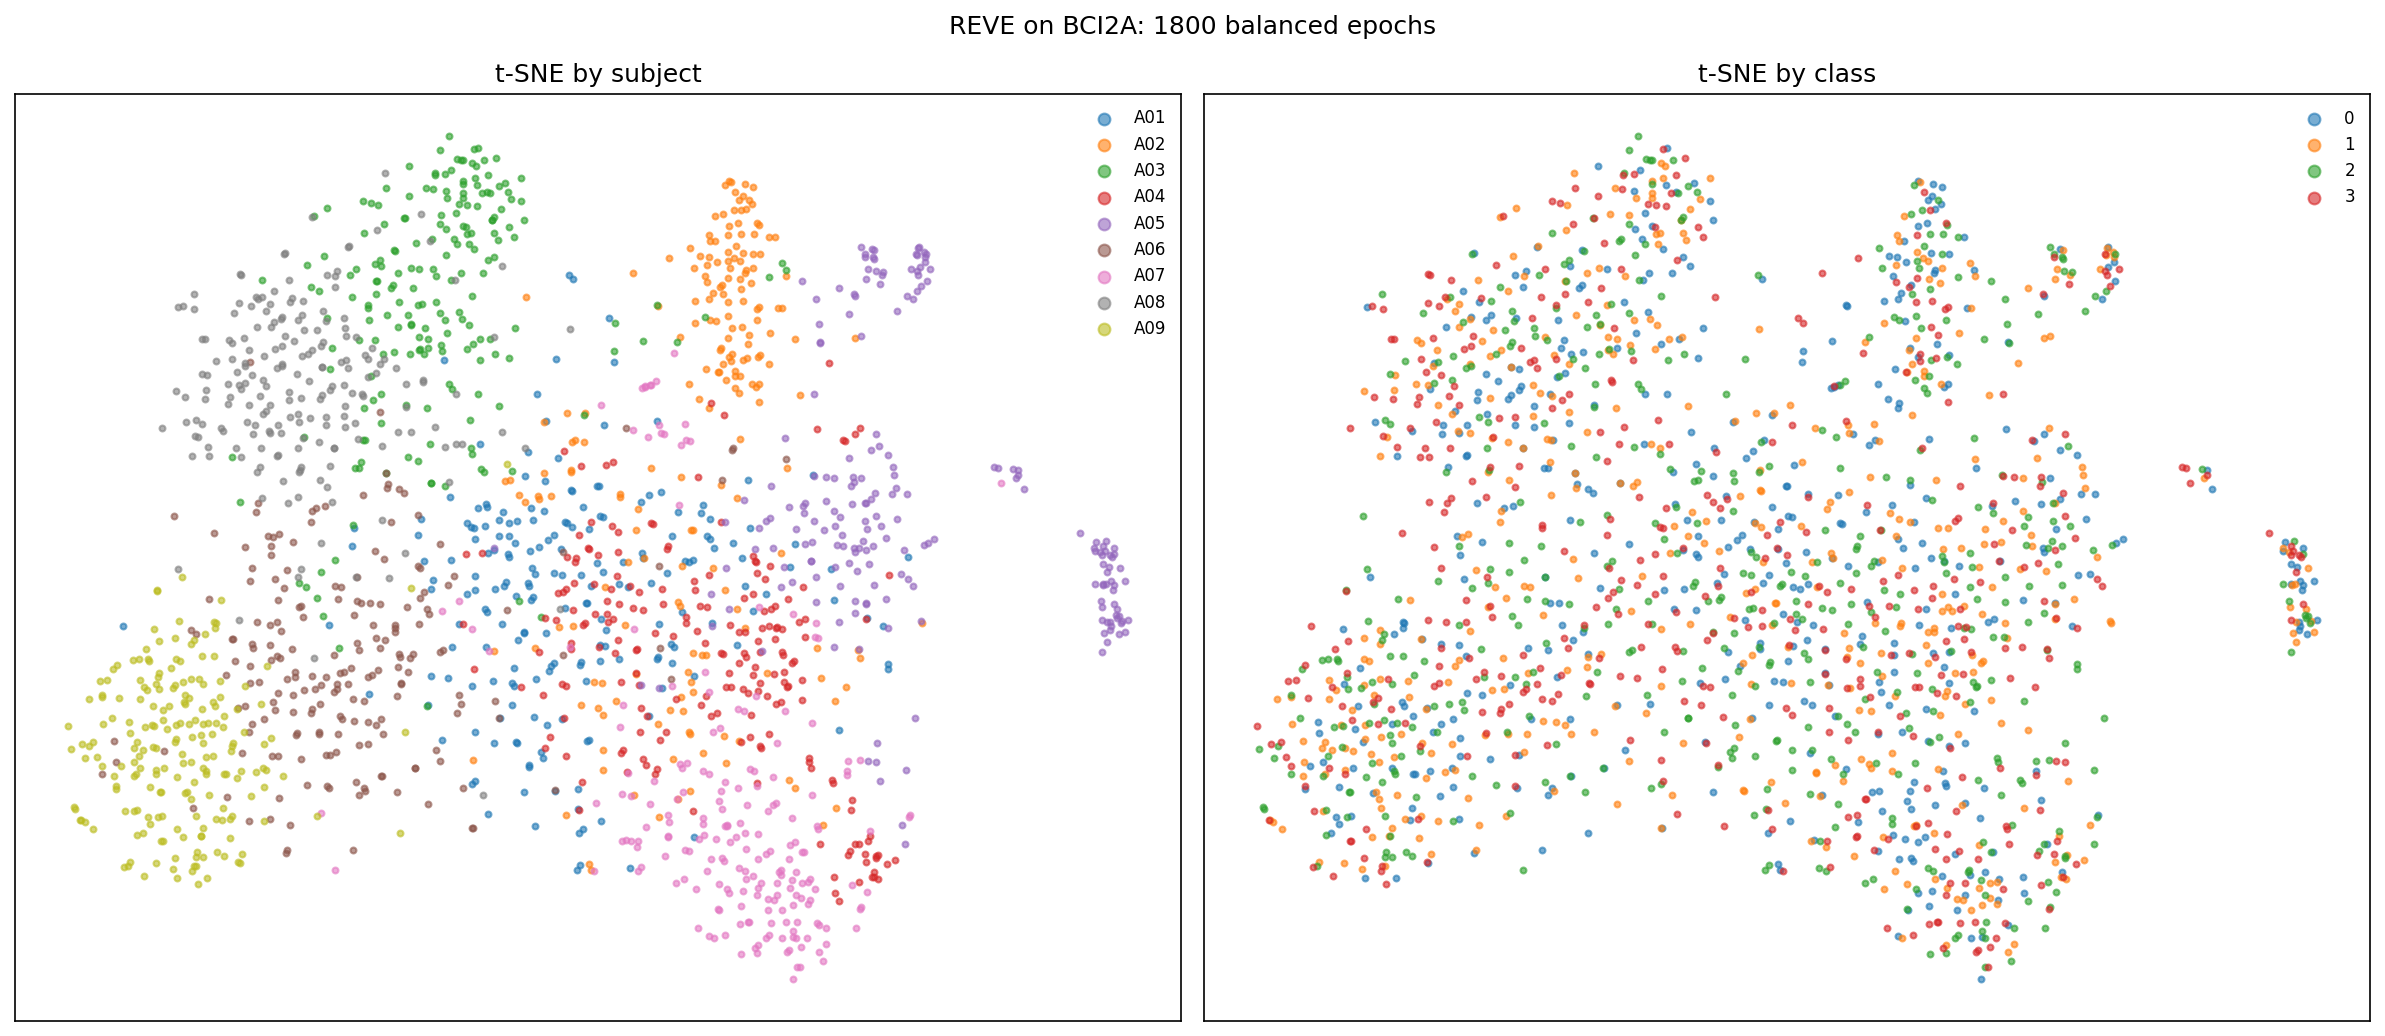

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7), dpi=150)

for subject_id in np.unique(subjects):
    mask = subjects == subject_id
    axes[0].scatter(projection[mask, 0], projection[mask, 1], s=8, alpha=0.6, label=str(subject_id)[:10])
axes[0].set_title("t-SNE by subject")
axes[0].legend(markerscale=2, fontsize=8, frameon=False)

for class_id in np.unique(labels):
    mask = labels == class_id
    axes[1].scatter(projection[mask, 0], projection[mask, 1], s=8, alpha=0.6, label=str(class_id))
axes[1].set_title("t-SNE by class")
axes[1].legend(markerscale=2, fontsize=8, frameon=False)

for axis in axes:
    axis.set_xticks([])
    axis.set_yticks([])

fig.suptitle(f"{MODEL_NAME.upper()} on {DATASET}: {len(projection)} balanced epochs")
fig.tight_layout()
plt.show()


## Optional model-shape summary

The following function is not executed automatically.

In [6]:
def build_model_summary(device=None):
    import pandas as pd

    device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    rows = []
    for model_name in MODEL_NAMES:
        for dataset in LMDB_PATHS:
            try:
                model, channel_mode = load_model(model_name, dataset, device)
                subject_id = get_subject_ids(Path(LMDB_PATHS[dataset]))[0]
                sample, _ = CustomDataset(
                    LMDB_PATHS[dataset],
                    [subject_id],
                    channel_mode=channel_mode,
                )[0]
                with torch.inference_mode():
                    x = sample.unsqueeze(0).to(device).float()
                    shape = tuple(model(model.wrapper.preprocess(x)).shape)
                parameters = sum(parameter.numel() for parameter in model.backbone.parameters()) / 1e6
                del model
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
            except Exception as error:
                parameters, shape = None, f"ERROR: {error}"
            rows.append({
                "model": model_name,
                "dataset": dataset,
                "encoder_M": parameters,
                "feature_shape": shape,
            })
    return pd.DataFrame(rows)
